# 第 21 课｜希腊字母全解析

> **数据身份**：固定随机种子生成的模拟教学数据，不是真实证券行情。  
> **环境**：`pkm-quant` · Python 3.11 · 默认离线运行。  
> **课程原始材料**：`21_youtube-jhLFiq5FAvY/index.html`  
> **所属模块**：P1-M4 · 随机模型与衍生品风险

## 本节量化问题

Delta、Gamma、Theta 和 Vega 如何共同描述期权风险？

## 准确定义与策略报告位置

Greeks 是价格对输入变量的局部偏导数，用于近似价格变化、构造对冲和管理风险暴露。

- **核心关系**：Delta=∂V/∂S，Gamma=∂²V/∂S²，Theta=∂V/∂t，Vega=∂V/∂σ。
- **写入报告**：方向、曲率、时间和波动率风险
- **P2 衔接**：P2 第 33、40–41 课：矩阵计算和敏感度可视化。


## 运行环境与数据契约

先确认项目、数据目录和数据身份。后续联网数据源必须通过适配层进入，不能改变本 Notebook 的研究计算口径。

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "fixtures").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "fixtures"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RANDOM_SEED = 365
print("项目:", ROOT)
print("数据:", DATA_DIR)
print("数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情")


项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations
数据: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations/data/fixtures
数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情


## 同一合约的四个局部敏感度

Theta 以每天计，Vega 以波动率变化 1 个百分点计；不同资料的单位定义可能不同。

In [2]:
from src.quant_core import black_scholes_greeks

greeks = black_scholes_greeks(
    spot=100.0,
    strike=100.0,
    maturity=0.5,
    rate=0.02,
    volatility=0.25,
)
display(pd.Series(greeks))

delta                 0.557628
gamma                 0.022332
theta_per_day        -0.021763
vega_per_vol_point    0.279147
dtype: float64

## Delta 和 Gamma 随现价变化

这是局部风险曲线。大幅价格变化时应重新计算，而不能用初始 Delta 线性外推。

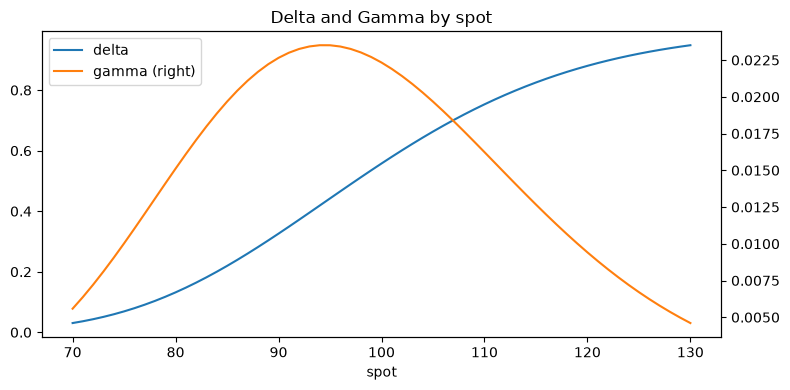

In [3]:
spots = np.linspace(70.0, 130.0, 61)
surface = pd.DataFrame([
    {"spot": spot, **black_scholes_greeks(spot, 100.0, 0.5, 0.02, 0.25)}
    for spot in spots
])
ax = surface.plot(x="spot", y=["delta", "gamma"], secondary_y="gamma", figsize=(8, 4), title="Delta and Gamma by spot")
plt.tight_layout()
plt.show()

## 方法边界与阶段验收

Greeks 是局部近似，会随现价、期限和波动变化；大幅跳跃和离散调仓会产生对冲误差。

完成本课后应能：

1. 不看课程材料准确解释核心概念和公式符号；
2. 用小样本手工核对 Notebook 的关键结果；
3. 说明结果能支持什么判断、不能支持什么判断；
4. 指出它在策略报告中的位置，以及仍缺少的数据、成本或稳健性证据。
